# Eje 8a — Griegas (Black–Scholes)

Derivados Financieros · QUANt UCEMA

Las griegas miden sensibilidades del precio. Acá: fórmulas analíticas (`Codigo.analytics`)
y verificación por diferencias finitas (bumps).

**Plan**
1. Definiciones
2. Analíticas vs bumps
3. Curvas vs $S$ (call y put)
4. Resumen

## 1) Setup

In [1]:
import math
import sys
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

print("OK")

OK


In [2]:
from Codigo.pricing import opcion_europea_bs
from Codigo.analytics.gregas_bs import (
    delta_bs, gamma_bs, vega_bs, theta_bs, rho_bs,
)

## 2) Definiciones

| Griega | Definición | Intuición |
|--------|------------|-----------|
| Delta $\Delta$ | $\partial V/\partial S$ | cobertura en acciones |
| Gamma $\Gamma$ | $\partial^2 V/\partial S^2$ | estabilidad del delta |
| Vega | $\partial V/\partial\sigma$ | exposición a vol |
| Theta $\Theta$ | $\partial V/\partial t$ | decaimiento temporal |
| Rho | $\partial V/\partial r$ | sensibilidad a tasa |

Bump numérico (centrado):

$$
\Delta \approx \frac{V(S+h)-V(S-h)}{2h}
$$

## 3) Parámetros y check en un punto

In [3]:
tipo = "C"
S, K, T = 100.0, 100.0, 1.0
r, sigma, div = 0.05, 0.25, 0.0
h_S, h_sig, h_r, h_t = 0.5, 1e-4, 1e-4, 1e-4

def bump_delta():
    up = opcion_europea_bs(tipo, S+h_S, K, T, r, sigma, div)
    dn = opcion_europea_bs(tipo, S-h_S, K, T, r, sigma, div)
    return (up - dn) / (2 * h_S)

def bump_gamma():
    up = opcion_europea_bs(tipo, S+h_S, K, T, r, sigma, div)
    mid = opcion_europea_bs(tipo, S, K, T, r, sigma, div)
    dn = opcion_europea_bs(tipo, S-h_S, K, T, r, sigma, div)
    return (up - 2*mid + dn) / (h_S**2)

def bump_vega():
    up = opcion_europea_bs(tipo, S, K, T, r, sigma+h_sig, div)
    dn = opcion_europea_bs(tipo, S, K, T, r, sigma-h_sig, div)
    return (up - dn) / (2 * h_sig)

rows = []
for name, anal, bump in [
    ("Delta", delta_bs(tipo,S,K,T,r,sigma,div), bump_delta()),
    ("Gamma", gamma_bs(tipo,S,K,T,r,sigma,div), bump_gamma()),
    ("Vega", vega_bs(tipo,S,K,T,r,sigma,div), bump_vega()),
]:
    rows.append({"griega": name, "analitica": anal, "bump": bump, "diff": anal-bump})
pd.DataFrame(rows).round(8)

,griega,analitica,bump,diff
0,Delta,0.627409,0.627395,1.451000e-05
1,Gamma,0.015137,0.015137,2.700000e-07
2,Vega,37.841983,37.841983,1.400000e-07


## 4) Curvas vs spot

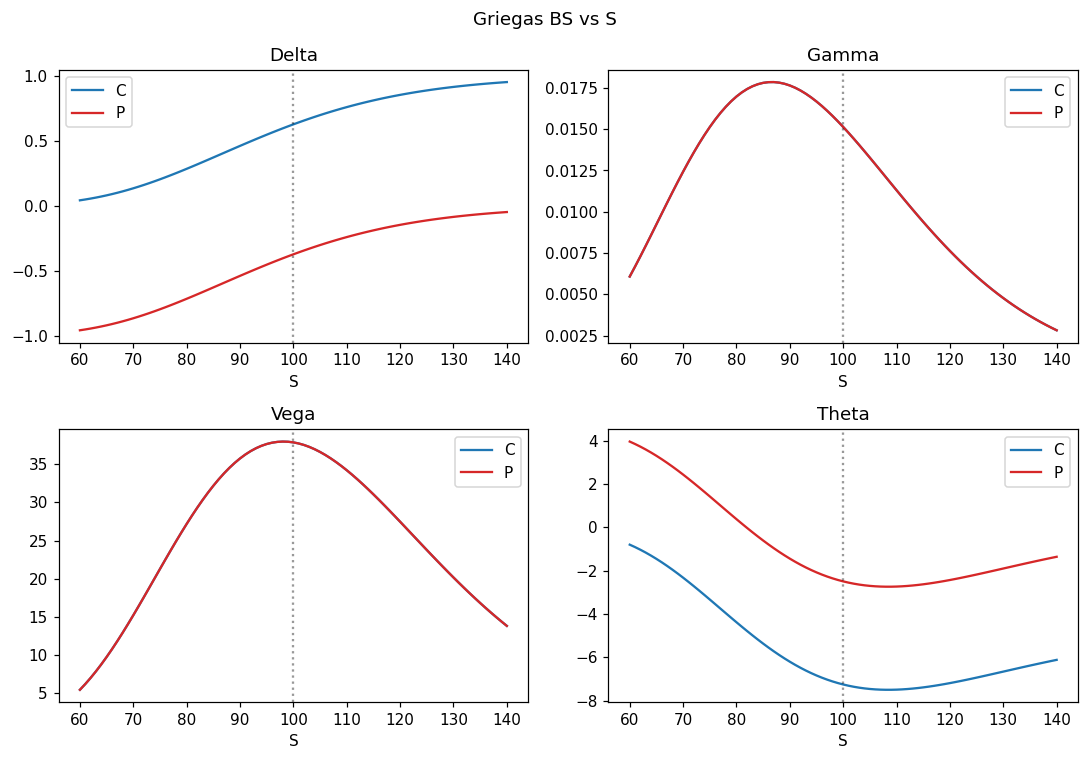

In [4]:
S_grid = np.linspace(60, 140, 81)
fig, axes = plt.subplots(2, 2, figsize=(10, 7), dpi=110)
for tipo_g, color in [("C", "C0"), ("P", "C3")]:
    d = [delta_bs(tipo_g,s,K,T,r,sigma,div) for s in S_grid]
    g = [gamma_bs(tipo_g,s,K,T,r,sigma,div) for s in S_grid]
    v = [vega_bs(tipo_g,s,K,T,r,sigma,div) for s in S_grid]
    th = [theta_bs(tipo_g,s,K,T,r,sigma,div) for s in S_grid]
    axes[0,0].plot(S_grid, d, color=color, label=tipo_g)
    axes[0,1].plot(S_grid, g, color=color, label=tipo_g)
    axes[1,0].plot(S_grid, v, color=color, label=tipo_g)
    axes[1,1].plot(S_grid, th, color=color, label=tipo_g)
for ax, title in zip(axes.ravel(), ["Delta", "Gamma", "Vega", "Theta"]):
    ax.axvline(K, color="k", ls=":", alpha=0.4)
    ax.set_title(title); ax.set_xlabel("S"); ax.legend()
plt.suptitle("Griegas BS vs S"); plt.tight_layout(); plt.show()

## Resumen

- Analítico BS = gold standard para europeas; bumps validan implementación.
- Call: $\Delta\in(0,1)$; put: $\Delta\in(-1,0)$; $\Gamma$ y Vega máximos cerca de ATM.
- Theta suele ser negativo para long options (decaimiento).

**Ejercicio:** calculá Rho analítico (`rho_bs`) y por bump en $r$; ¿dónde es más grande en $S$?

**Siguiente:** **08b** — PnL explanation.